In [3]:
import tensorflow as tf
from tensorflow import keras
from keras.layers import Input,Conv2D,MaxPooling2D,Dense,Flatten
from keras.models import Sequential
import matplotlib.pyplot as plt
import pandas as pd

In [5]:
train=pd.read_csv('/content/sign_mnist_train.csv')
test=pd.read_csv('/content/sign_mnist_test.csv')

In [6]:
x_train=train.drop('label',axis=1).values
y_train=train['label'].values
x_test=test.drop('label',axis=1).values
y_test=test['label'].values

In [7]:
x_train.shape

(27455, 784)

In [8]:
x_test.shape

(7172, 784)

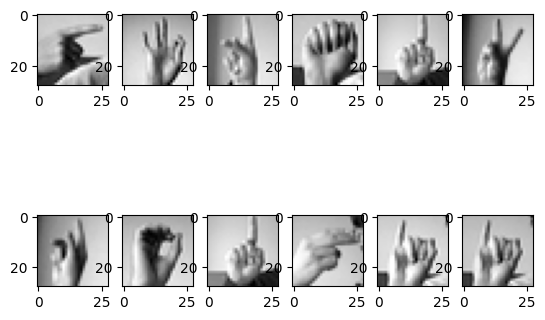

In [9]:
for i in range(12):
    plt.subplot(2,6,i+1)
    plt.imshow(x_test[i].reshape(28,28),cmap='gray')
plt.show()

In [10]:
x_train=x_train.astype('float')/255.0

In [11]:
x_test=x_test.astype('float')/255.0

In [12]:
x_train.shape

(27455, 784)

In [13]:
x_train=x_train.reshape(-1,28,28,1)

In [14]:
x_test=x_test.reshape(-1,28,28,1)

In [15]:
x_test.shape

(7172, 28, 28, 1)

In [16]:
import numpy as np
np.unique(y_train)

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24])

In [17]:
model=Sequential([
    Input(shape=(28,28,1)),
    Conv2D(16,kernel_size=(3,3),activation='relu'),
    MaxPooling2D(pool_size=(2,2)),
    Flatten(),
    Dense(8,activation='relu'),
    Dense(25,activation='softmax')
])

In [18]:
model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

In [19]:
history=model.fit(x_train,y_train,epochs=16,validation_split=0.2)

Epoch 1/16
687/687 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.0459 - loss: 3.2074 - val_accuracy: 0.0479 - val_loss: 3.1986
Epoch 2/16
687/687 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.0469 - loss: 3.1936 - val_accuracy: 0.0479 - val_loss: 3.1899
Epoch 3/16
687/687 ━━━━━━━━━━━━━━━━━━━━ 12s 17ms/step - accuracy: 0.0455 - loss: 3.1871 - val_accuracy: 0.0479 - val_loss: 3.1851
Epoch 4/16
687/687 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.0469 - loss: 3.1834 - val_accuracy: 0.0479 - val_loss: 3.1824
Epoch 5/16
687/687 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - accuracy: 0.0463 - loss: 3.1811 - val_accuracy: 0.0479 - val_loss: 3.1806
Epoch 6/16
687/687 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.0469 - loss: 3.1796 - val_accuracy: 0.0479 - val_loss: 3.1794
Epoch 7/16
687/687 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.0469 - loss: 3.1786 - val_accuracy: 0.0479 - val_loss: 3.1786
Epoch 8/16
687/687 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.0459 - loss: 3.1779 - va

In [20]:
loss,acc=model.evaluate(x_test,y_test)
print("Test Accuracy:",acc)

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.0201 - loss: 3.2011
Test Accuracy: 0.020078081637620926


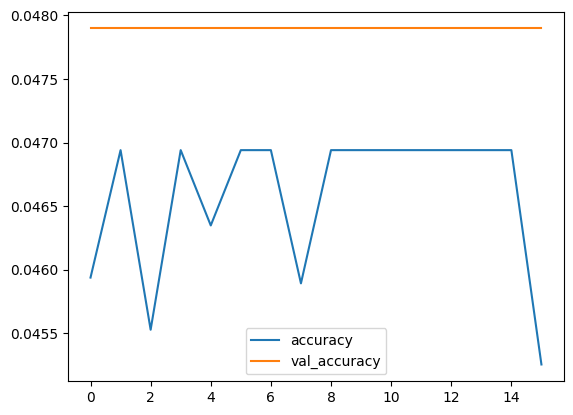

In [21]:
plt.plot(history.history['accuracy'],label='accuracy')
plt.plot(history.history['val_accuracy'],label='val_accuracy')
plt.legend()
plt.show()

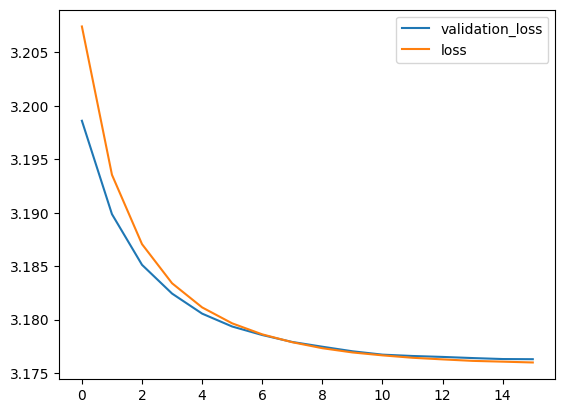

In [22]:
plt.plot(history.history['val_loss'],label='validation_loss')
plt.plot(history.history['loss'],label='loss')
plt.legend()
plt.show()

## Conclusion
1. In this project, we used a Convolutional Neural Network (CNN) to classify sign language hand gesture images.
2. We converted the pixel values into a range from 0 to 1 to make training easier.
3. The convolution layer learns image features, and the max pooling layer reduces the size of the feature maps.
4. We used ReLU in the hidden layers and Softmax in the output layer to predict the gesture class.
5. We used sparse categorical crossentropy because the target labels are integers, and Adam to update the model weights.
6. Finally, we evaluated the model on the separate test dataset and plotted training and validation accuracy and loss to understand its performance.